# Univariate analysis

In [1]:
import pandas as pd
import sys
import numpy as np

sys.path.append("..")

import matplotlib.pyplot as plt
import seaborn as sns
from src.data.loader import load_phenotypes
from src.config import MORE_EXPRESSED_GENES, L1_REGULATORS, L1_REGULATORS_WITH_2_STEPS_FROM_MECP2
from src.data.loader import load_all_regions


In [2]:
df = load_phenotypes()

In [3]:
df.head(10)

,SUBJID,SEX,AGE,DTHHRDY
0,GTEX-1117F,2,60-69,4.0
1,GTEX-111CU,1,50-59,0.0
2,GTEX-111FC,1,60-69,1.0
3,GTEX-111VG,1,60-69,3.0
4,GTEX-111YS,1,60-69,0.0
5,GTEX-1122O,2,60-69,0.0
6,GTEX-1128S,2,60-69,2.0
7,GTEX-113IC,1,60-69,NaN
8,GTEX-113JC,2,50-59,2.0
9,GTEX-117XS,1,60-69,2.0


In [4]:
df.describe()

,SEX,DTHHRDY
count,981.000000,962.000000
mean,1.333333,1.209979
std,0.471645,1.448234
min,1.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,0.000000
75%,2.000000,2.000000
max,2.000000,4.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SUBJID   981 non-null    str    
 1   SEX      981 non-null    int64  
 2   AGE      981 non-null    str    
 3   DTHHRDY  962 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 30.8 KB


In [6]:
df["SEX"].value_counts()

SEX
1    654
2    327
Name: count, dtype: int64

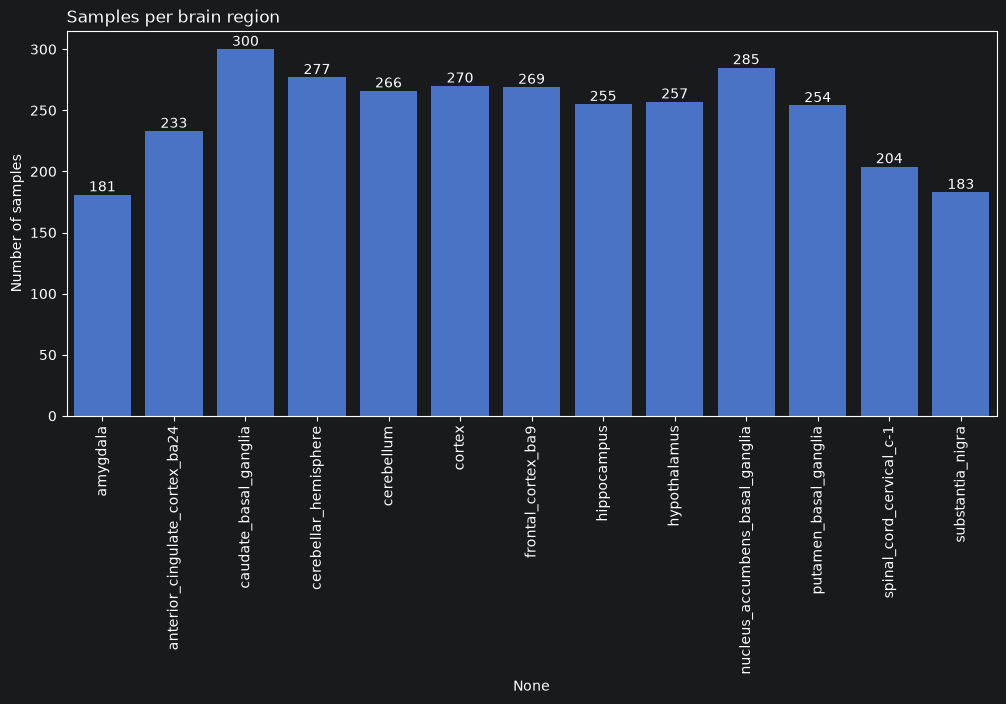

In [7]:

samples_per_region = pd.Series({region.value: len(expr.columns) - 2 for region, expr in load_all_regions(nrows=0).items()})

plt.figure(figsize=(12, 5))
ax = sns.barplot(x=samples_per_region.index, y=samples_per_region.values)
ax.bar_label(ax.containers[0])
plt.xticks(rotation=90)
plt.ylabel("Number of samples")
plt.title("Samples per brain region", loc="left")
plt.show()

<Axes: xlabel='SEX', ylabel='count'>

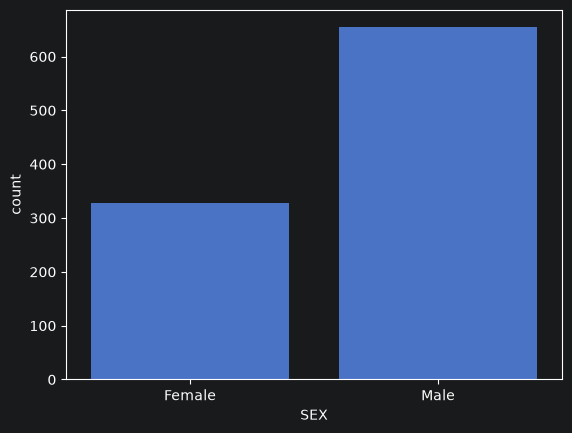

In [8]:
sns.countplot(x=df["SEX"].replace({1: "Male", 2: "Female"}))

<Axes: xlabel='AGE', ylabel='count'>

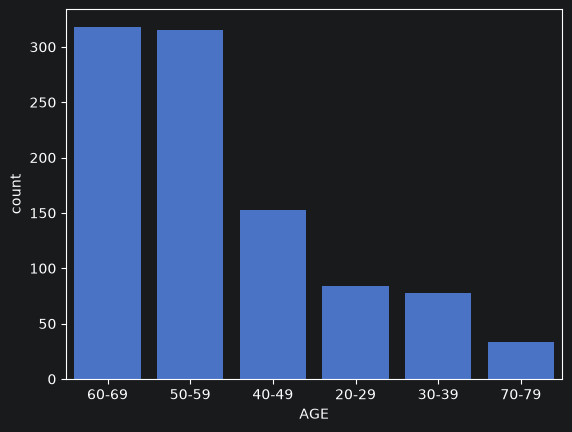

In [9]:
sns.countplot(x=df["AGE"])

<Axes: xlabel='DTHHRDY', ylabel='count'>

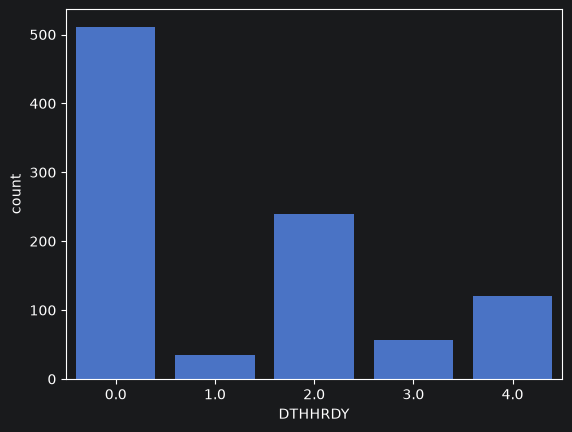

In [10]:
sns.countplot(x=df["DTHHRDY"])

In [11]:
from src.data.loader import load_all_regions
import pandas as pd

regions = load_all_regions(nrows=None)

In [12]:
genes = []
for region, expr in regions.items():
    g = expr[expr["Description"].isin(L1_REGULATORS + MORE_EXPRESSED_GENES)]
    g = g.drop(columns="Name").melt(id_vars="Description", var_name="sample", value_name="TPM")
    g["region"] = region.value
    genes.append(g)

genes = pd.concat(genes)
print(genes.shape)
genes.head()

(352506, 4)


,Description,sample,TPM,region
0,KDM1A,GTEX-1117F-0011-R4b-SM-GI4VM,8.842710,amygdala
1,RUNX3,GTEX-1117F-0011-R4b-SM-GI4VM,0.967832,amygdala
2,PABPC4,GTEX-1117F-0011-R4b-SM-GI4VM,24.448600,amygdala
3,TUT4,GTEX-1117F-0011-R4b-SM-GI4VM,5.511600,amygdala
4,HENMT1,GTEX-1117F-0011-R4b-SM-GI4VM,3.591080,amygdala


In [13]:
expression = pd.concat(
    [expr.set_index(["Name", "Description"]) for expr in regions.values()], axis=1
)
expression.shape

(74628, 3234)

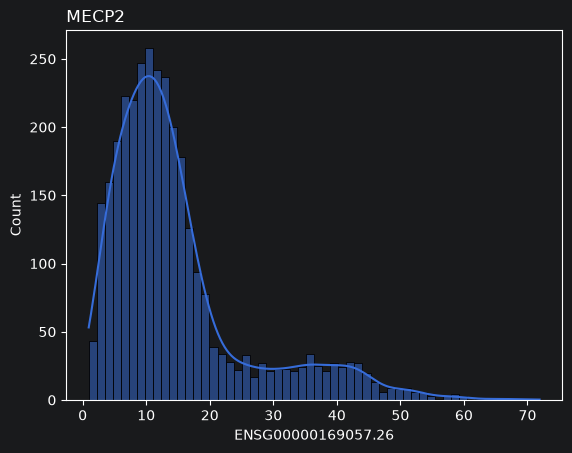

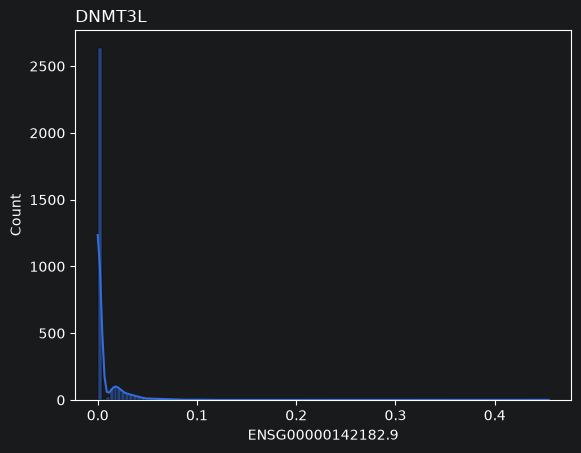

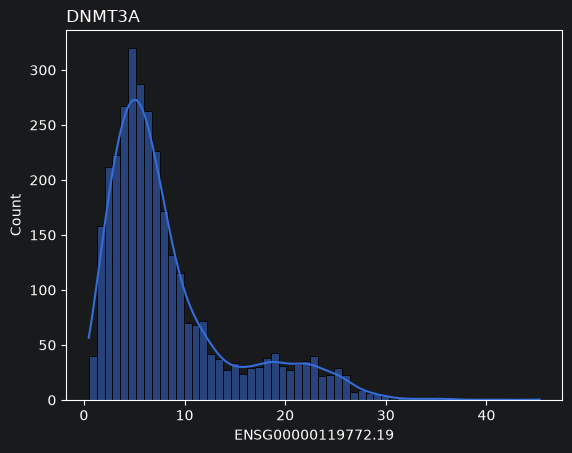

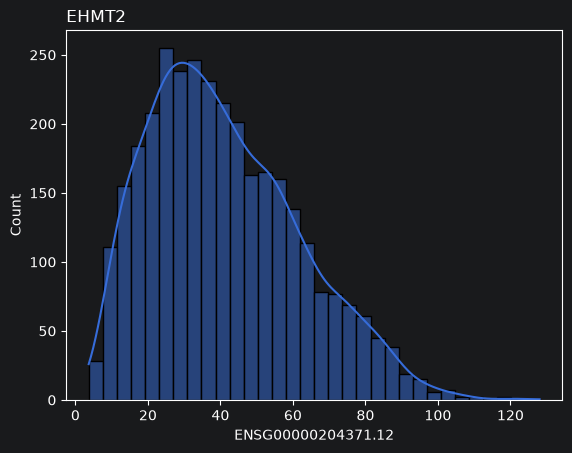

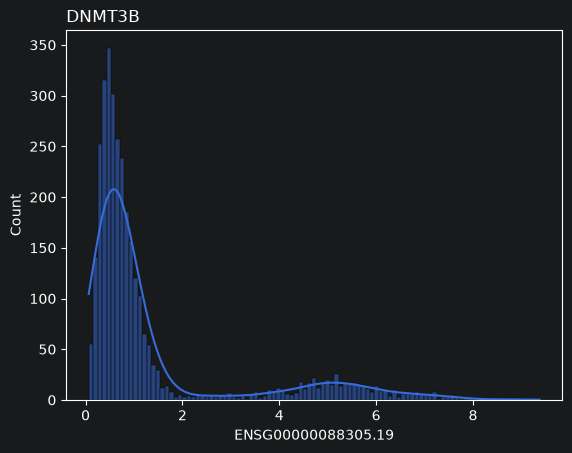

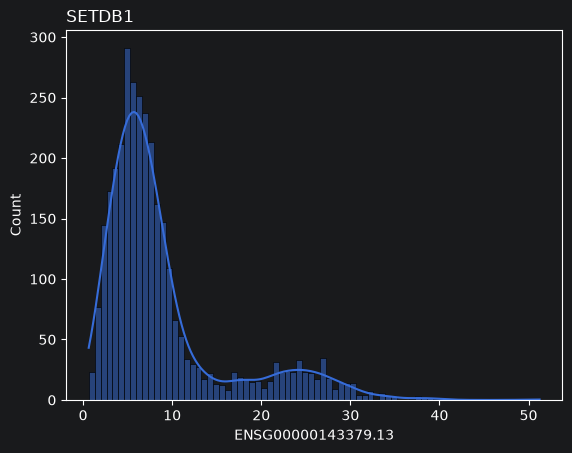

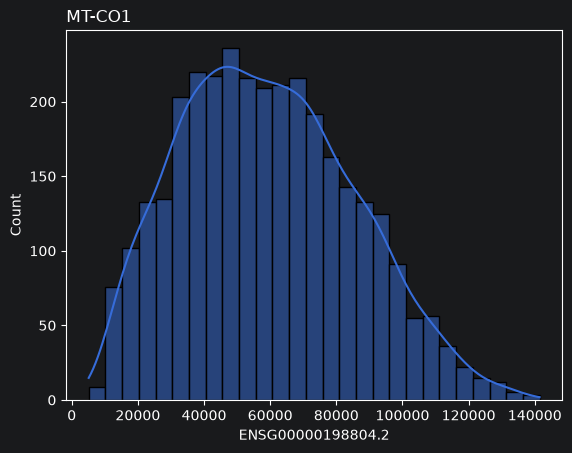

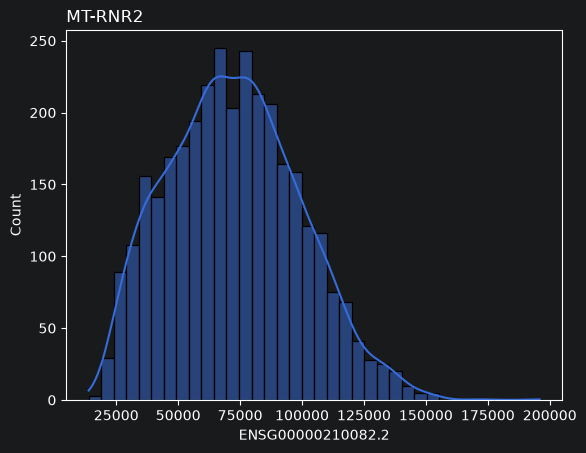

In [14]:
for gene in L1_REGULATORS_WITH_2_STEPS_FROM_MECP2 + MORE_EXPRESSED_GENES:
    tpm = expression.xs(gene, level="Description").iloc[0]
    sns.histplot(tpm, kde=True)
    plt.title(gene, loc="left")
    plt.show()

In [15]:
l1 = genes[genes["Description"].isin(L1_REGULATORS)]

l1_variation = l1.groupby("Description")["TPM"].agg(["mean", "std", "var", "median", "min","max"])
l1_variation = l1_variation.sort_values("var", ascending=False)
pd.set_option("display.max_rows", None)
l1_variation

,mean,std,var,median,min,max
Description,,,,,,
HSP90AA1,699.556733,648.457224,420496.771741,586.258500,50.301900,11038.900000
PABPN1,166.528361,101.949531,10393.706926,140.165000,13.837100,626.100000
HNRNPA2B1,139.159864,88.162079,7772.552110,114.512000,12.541700,572.068000
MATR3,123.531390,74.001400,5476.207229,108.693000,8.347910,511.379000
HNRNPL,106.704864,60.047510,3605.703460,94.197950,9.803010,397.647000
NCL,110.932614,54.372767,2956.397842,99.932550,12.974200,365.579000
XRCC6,100.042270,52.229826,2727.954733,92.680150,10.167900,317.946000
TRIM28,69.347144,49.966039,2496.605043,54.293700,6.497580,326.587000
UPF3A,51.561666,38.149064,1455.351081,38.059350,4.549770,196.008000
